In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

Mounted at /content/drive
PyTorch: 2.14.1+cu130
GPU available: True


In [2]:
from pathlib import Path
z = Path("/content/drive/MyDrive/plant-disease-cnn/data/archive.zip")
print(z.exists(), round(z.stat().st_size / 1e9, 2), "GB")

True 2.19 GB


In [3]:
import shutil, zipfile
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/plant-disease-cnn")
zip_src = PROJECT / "data" / "archive.zip"
zip_local = Path("/content/archive.zip")
out_dir = Path("/content/PlantVillage")

if not out_dir.exists():
    shutil.copy(zip_src, zip_local)          # copy zip from Drive (fast)
    with zipfile.ZipFile(zip_local) as z:
        for name in z.namelist():
            parts = name.split("/")
            if "color" in parts and not name.endswith("/"):
                target = out_dir.joinpath(*parts[parts.index("color") + 1:])
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(name) as src, open(target, "wb") as dst:
                    shutil.copyfileobj(src, dst)
    zip_local.unlink()                       # delete the zip copy

classes = sorted(d.name for d in out_dir.iterdir() if d.is_dir())
n_images = sum(1 for _ in out_dir.rglob("*.*"))
print(len(classes), "classes,", n_images, "images")

38 classes, 54305 images


In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from PIL import Image
from pathlib import Path
from collections import Counter

device = "cuda" if torch.cuda.is_available() else "cpu"
data_dir = Path("/content/PlantVillage")

# 1. List all images and their labels
classes = sorted(d.name for d in data_dir.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(classes)}

paths, labels = [], []
for c in classes:
      for p in sorted((data_dir / c).glob("*.*")):
        paths.append(p)
        labels.append(class_to_idx[c])

# 2. Split 70% train / 15% validation / 15% test (same class mix in each)
train_p, temp_p, train_y, temp_y = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=42)
val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=0.50, stratify=temp_y, random_state=42)

print("Train:", len(train_p), "| Val:", len(val_p), "| Test:", len(test_p))

# 3. Transforms
IMG_SIZE = 128
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# 4. Dataset class
class LeafDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

train_ds = LeafDataset(train_p, train_y, train_tf)
val_ds = LeafDataset(val_p, val_y, eval_tf)
test_ds = LeafDataset(test_p, test_y, eval_tf)

# 5. DataLoaders
BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

# 6. Class weights (to help with the uneven classes, used in training later)
counts = Counter(train_y)
class_weights = torch.tensor(
    [len(train_y) / (len(classes) * counts[i]) for i in range(len(classes))],
    dtype=torch.float32)

# 7. Check one batch
images, targets = next(iter(train_loader))
print("Images:", images.shape)
print("Labels:", targets.shape)

Train: 38013 | Val: 8146 | Test: 8146
Images: torch.Size([64, 3, 128, 128])
Labels: torch.Size([64])


In [5]:
import torch.nn as nn

class BaselineCNN(nn.Module):
    def __init__(self, num_classes=38):
        super().__init__()

        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            block(3, 32),     # 128 -> 64
            block(32, 64),    # 64  -> 32
            block(64, 128),   # 32  -> 16
            block(128, 256),  # 16  -> 8
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

model = BaselineCNN(num_classes=len(classes)).to(device)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

# Test on one batch
images, targets = next(iter(train_loader))
out = model(images.to(device))
print("Output shape:", out.shape)

BaselineCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0)

In [6]:
import math
import numpy as np
import torch.nn.functional as F
from concurrent.futures import ThreadPoolExecutor

# 1. Load + resize every image once
def load(p):
    img = Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(img, dtype=np.uint8)

def cache(paths):
    with ThreadPoolExecutor(8) as ex:
        arr = np.stack(list(ex.map(load, paths)))
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()

Xtr, Xva, Xte = cache(train_p).to(device), cache(val_p).to(device), cache(test_p).to(device)
ytr = torch.tensor(train_y, device=device)
yva = torch.tensor(val_y, device=device)
yte = torch.tensor(test_y, device=device)
print("Cached:", Xtr.shape, Xva.shape, Xte.shape)

# 2. GPU augmentation
mean_t = torch.tensor(mean, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(std, device=device).view(1, 3, 1, 1)

def augment(xb):
    B = xb.size(0)
    flip = torch.rand(B, device=device) < 0.5                       # random flip
    xb = torch.where(flip.view(B, 1, 1, 1), xb.flip(3), xb)
    ang = (torch.rand(B, device=device) * 2 - 1) * (20 * math.pi / 180)   # rotation
    cos, sin, zero = ang.cos(), ang.sin(), torch.zeros_like(ang)
    theta = torch.stack([torch.stack([cos, -sin, zero], 1),
                         torch.stack([sin, cos, zero], 1)], 1)
    grid = F.affine_grid(theta, xb.shape, align_corners=False)
    xb = F.grid_sample(xb, grid, padding_mode="reflection", align_corners=False)
    b = 1 + (torch.rand(B, 1, 1, 1, device=device) * 2 - 1) * 0.2   # brightness
    c = 1 + (torch.rand(B, 1, 1, 1, device=device) * 2 - 1) * 0.2   # contrast
    m = xb.mean((1, 2, 3), keepdim=True)
    return (((xb - m) * c + m) * b).clamp(0, 1)

# 3. Loaders that work like before
class GPULoader:
    def __init__(self, X, y, train):
        self.X, self.y, self.train = X, y, train
    def __len__(self):
        return math.ceil(len(self.X) / BATCH)
    def __iter__(self):
        n = len(self.X)
        idx = torch.randperm(n, device=device) if self.train else torch.arange(n, device=device)
        for i in range(0, n, BATCH):
            j = idx[i:i + BATCH]
            xb = self.X[j].float() / 255
            if self.train:
                xb = augment(xb)
            yield (xb - mean_t) / std_t, self.y[j]

train_loader = GPULoader(Xtr, ytr, True)
val_loader = GPULoader(Xva, yva, False)
test_loader = GPULoader(Xte, yte, False)

# 4. Fresh model
model = BaselineCNN(num_classes=len(classes)).to(device)

Cached: torch.Size([38013, 3, 128, 128]) torch.Size([8146, 3, 128, 128]) torch.Size([8146, 3, 128, 128])


In [7]:
print(device, torch.cuda.is_available())

cuda True


In [8]:
import time
import torch.nn as nn
import torch.optim as optim
from pathlib import Path

EPOCHS = 10
LR = 1e-3
save_path = "/content/drive/MyDrive/plant-disease-cnn/models/baseline_cnn.pth"
Path(save_path).parent.mkdir(parents=True, exist_ok=True)
use_amp = (device == "cuda")

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            with torch.autocast(device_type="cuda", enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step(va_acc)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    saved = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save({"model_state": model.state_dict(), "classes": classes}, save_path)
        saved = " <- saved"

    print(f"Epoch {epoch}/{EPOCHS} | "
          f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} | "
          f"{time.time() - t0:.0f}s{saved}")

print("Best validation accuracy:", round(best_val_acc, 4))

Epoch 1/10 | train loss 1.680 acc 0.545 | val loss 1.129 acc 0.643 | 20s <- saved
Epoch 2/10 | train loss 0.803 acc 0.761 | val loss 0.686 acc 0.790 | 19s <- saved
Epoch 3/10 | train loss 0.545 acc 0.827 | val loss 0.435 acc 0.873 | 20s <- saved
Epoch 4/10 | train loss 0.429 acc 0.864 | val loss 0.416 acc 0.857 | 20s
Epoch 5/10 | train loss 0.356 acc 0.884 | val loss 0.536 acc 0.808 | 21s
Epoch 6/10 | train loss 0.306 acc 0.899 | val loss 0.621 acc 0.774 | 20s
Epoch 7/10 | train loss 0.203 acc 0.933 | val loss 0.241 acc 0.921 | 20s <- saved
Epoch 8/10 | train loss 0.190 acc 0.935 | val loss 0.178 acc 0.946 | 20s <- saved
Epoch 9/10 | train loss 0.174 acc 0.941 | val loss 0.178 acc 0.942 | 21s
Epoch 10/10 | train loss 0.158 acc 0.947 | val loss 0.176 acc 0.939 | 20s
Best validation accuracy: 0.9456


Test accuracy: 0.9509


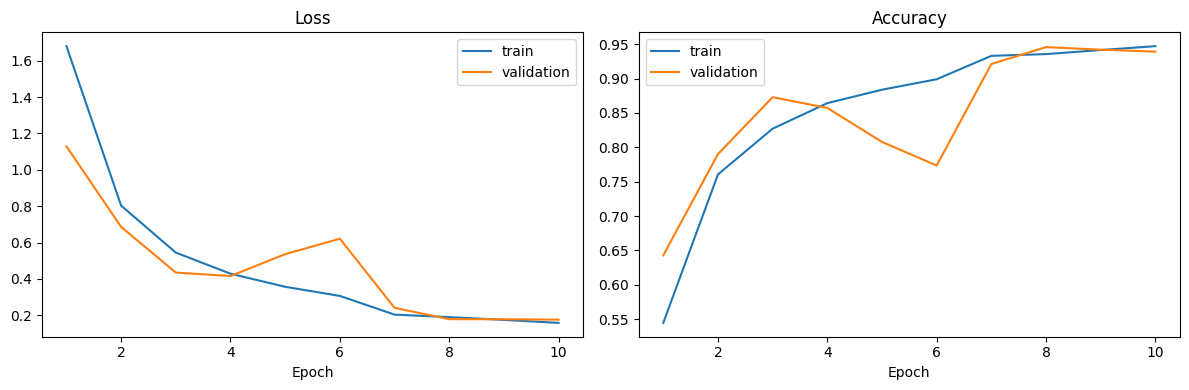

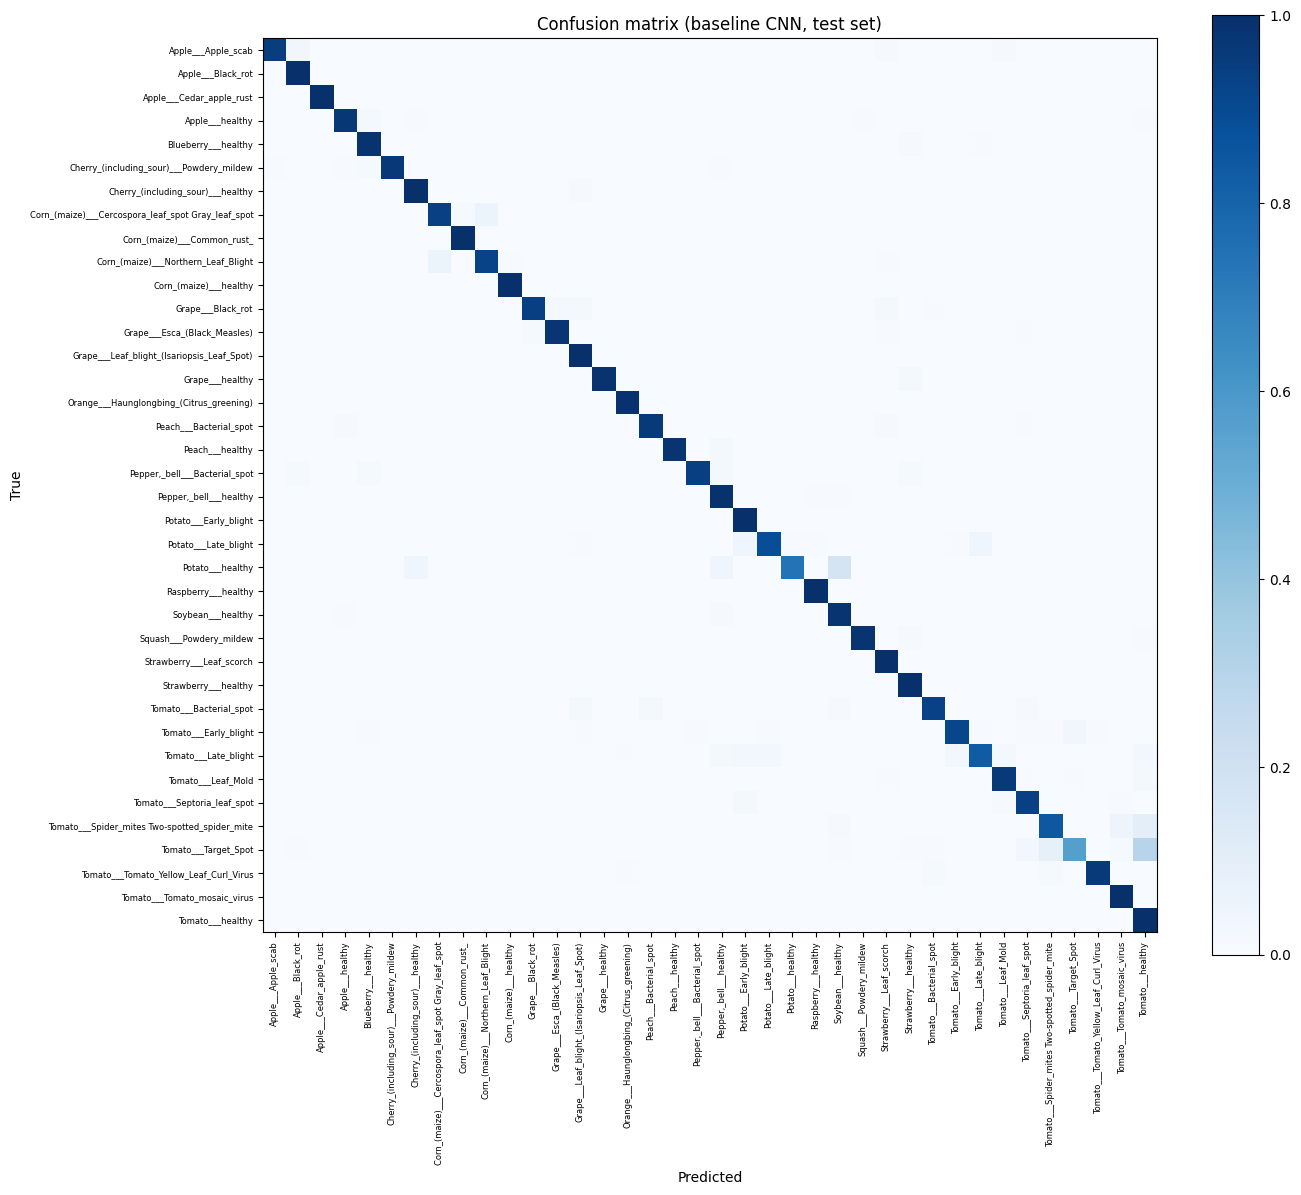

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.978     0.947     0.962        94
                                 Apple___Black_rot      0.930     1.000     0.964        93
                          Apple___Cedar_apple_rust      1.000     1.000     1.000        41
                                   Apple___healthy      0.960     0.972     0.966       246
                               Blueberry___healthy      0.957     0.987     0.972       226
          Cherry_(including_sour)___Powdery_mildew      0.994     0.968     0.981       158
                 Cherry_(including_sour)___healthy      0.969     0.992     0.981       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.889     0.935     0.911        77
                       Corn_(maize)___Common_rust_      0.994     1.000     0.997       179
               Corn_(maize)___Northern_Leaf_Blight      0.971     0.925     0.9

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path

OUT = Path("/content/drive/MyDrive/plant-disease-cnn/outputs")
OUT.mkdir(parents=True, exist_ok=True)

# 1. Load the best saved model
ckpt = torch.load(save_path, map_location=device)
model.load_state_dict(ckpt["model_state"])
model.eval()

# 2. Predict on the test set
preds, trues = [], []
with torch.no_grad():
    for x, y in test_loader:
        with torch.autocast(device_type="cuda", enabled=use_amp):
            out = model(x)
        preds.append(out.argmax(1).cpu())
        trues.append(y.cpu())
preds = torch.cat(preds).numpy()
trues = torch.cat(trues).numpy()
print("Test accuracy:", round((preds == trues).mean(), 4))

# 3. Training curves
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history["train_loss"], label="train")
ax[0].plot(ep, history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(ep, history["train_acc"], label="train")
ax[1].plot(ep, history["val_acc"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig(OUT / "training_curves.png", dpi=150)
plt.show()

# 4. Confusion matrix (each row adds up to 1)
cm = confusion_matrix(trues, preds)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(cm_norm, cmap="Blues")
ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90, fontsize=6)
ax.set_yticklabels(classes, fontsize=6)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Confusion matrix (baseline CNN, test set)")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", dpi=150)
plt.show()

# 5. Per-class report and the 5 weakest classes
print(classification_report(trues, preds, target_names=classes, digits=3))

per_class = cm.diagonal() / cm.sum(axis=1)
print("Weakest classes:")
for i in np.argsort(per_class)[:5]:
    print(f"  {classes[i]}: {per_class[i]:.3f} ({cm[i].sum()} test images)")

In [10]:
!ls -lh /content/drive/MyDrive/plant-disease-cnn/models /content/drive/MyDrive/plant-disease-cnn/outputs

/content/drive/MyDrive/plant-disease-cnn/models:
total 1.6M
-rw------- 1 root root 1.6M Nov 20 13:46 baseline_cnn.pth

/content/drive/MyDrive/plant-disease-cnn/outputs:
total 312K
-rw------- 1 root root 234K Nov 20 13:48 confusion_matrix.png
-rw------- 1 root root  78K Nov 20 13:47 training_curves.png


In [8]:
import time
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from pathlib import Path

use_amp = (device == "cuda")
save_path_tl = "/content/drive/MyDrive/plant-disease-cnn/models/mobilenetv2.pth"
Path(save_path_tl).parent.mkdir(parents=True, exist_ok=True)

# 1. Pretrained MobileNetV2 with a new 38-class output layer
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, len(classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# 2. One pass over a loader (train or validation)
def run_epoch(loader, train, optimizer=None, freeze_backbone=False):
    model.train() if train else model.eval()
    if train and freeze_backbone:
        model.features.eval()          # keep the pretrained part fixed
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            with torch.autocast(device_type="cuda", enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history_tl = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best = {"acc": 0.0}

# 3. Train in two stages
def train_stage(name, epochs, lr, freeze_backbone):
    for p in model.features.parameters():
        p.requires_grad = not freeze_backbone
    optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(train_loader, True, optimizer, freeze_backbone)
        va_loss, va_acc = run_epoch(val_loader, False)

        history_tl["train_loss"].append(tr_loss)
        history_tl["val_loss"].append(va_loss)
        history_tl["train_acc"].append(tr_acc)
        history_tl["val_acc"].append(va_acc)

        saved = ""
        if va_acc > best["acc"]:
            best["acc"] = va_acc
            torch.save({"model_state": model.state_dict(), "classes": classes}, save_path_tl)
            saved = " <- saved"

        print(f"[{name}] Epoch {epoch}/{epochs} | "
              f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} | "
              f"{time.time() - t0:.0f}s{saved}")

train_stage("Stage A: head only", epochs=3, lr=1e-3, freeze_backbone=True)
train_stage("Stage B: fine-tune all", epochs=7, lr=1e-4, freeze_backbone=False)

print("Best validation accuracy:", round(best["acc"], 4))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 99.5MB/s]


[Stage A: head only] Epoch 1/3 | train loss 0.791 acc 0.829 | val loss 0.410 acc 0.888 | 14s <- saved
[Stage A: head only] Epoch 2/3 | train loss 0.345 acc 0.906 | val loss 0.302 acc 0.918 | 10s <- saved
[Stage A: head only] Epoch 3/3 | train loss 0.277 acc 0.919 | val loss 0.255 acc 0.932 | 10s <- saved
[Stage B: fine-tune all] Epoch 1/7 | train loss 0.424 acc 0.885 | val loss 0.159 acc 0.950 | 34s <- saved
[Stage B: fine-tune all] Epoch 2/7 | train loss 0.100 acc 0.968 | val loss 0.103 acc 0.965 | 31s <- saved
[Stage B: fine-tune all] Epoch 3/7 | train loss 0.064 acc 0.980 | val loss 0.075 acc 0.977 | 31s <- saved
[Stage B: fine-tune all] Epoch 4/7 | train loss 0.041 acc 0.988 | val loss 0.062 acc 0.981 | 31s <- saved
[Stage B: fine-tune all] Epoch 5/7 | train loss 0.032 acc 0.991 | val loss 0.055 acc 0.983 | 31s <- saved
[Stage B: fine-tune all] Epoch 6/7 | train loss 0.026 acc 0.992 | val loss 0.048 acc 0.986 | 31s <- saved
[Stage B: fine-tune all] Epoch 7/7 | train loss 0.020 acc 

Model             Test accuracy    Macro F1
Baseline CNN             0.9509      0.9413
MobileNetV2              0.9870      0.9827

Baseline's weakest classes (recall: baseline -> MobileNetV2):
  Tomato___Target_Spot: 0.564 -> 0.981
  Potato___healthy: 0.739 -> 0.957
  Tomato___Late_blight: 0.829 -> 0.892
  Tomato___Spider_mites Two-spotted_spider_mite: 0.845 -> 0.980
  Potato___Late_blight: 0.887 -> 0.973


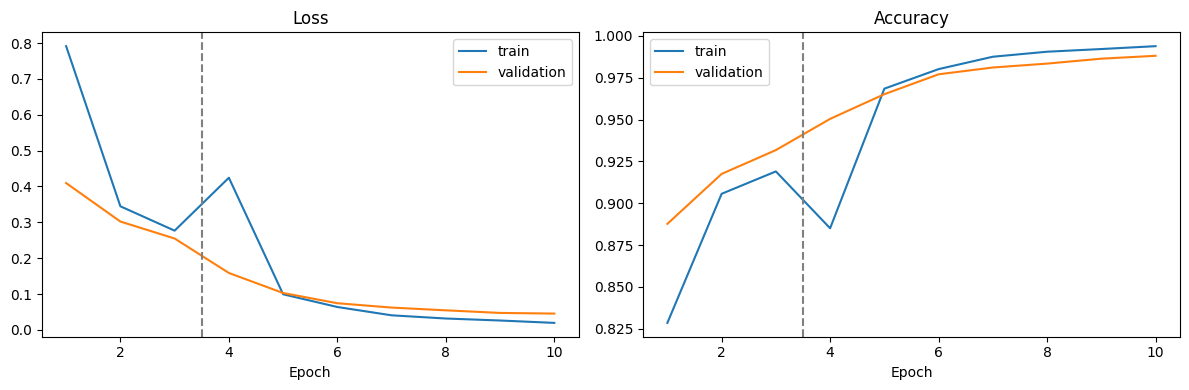

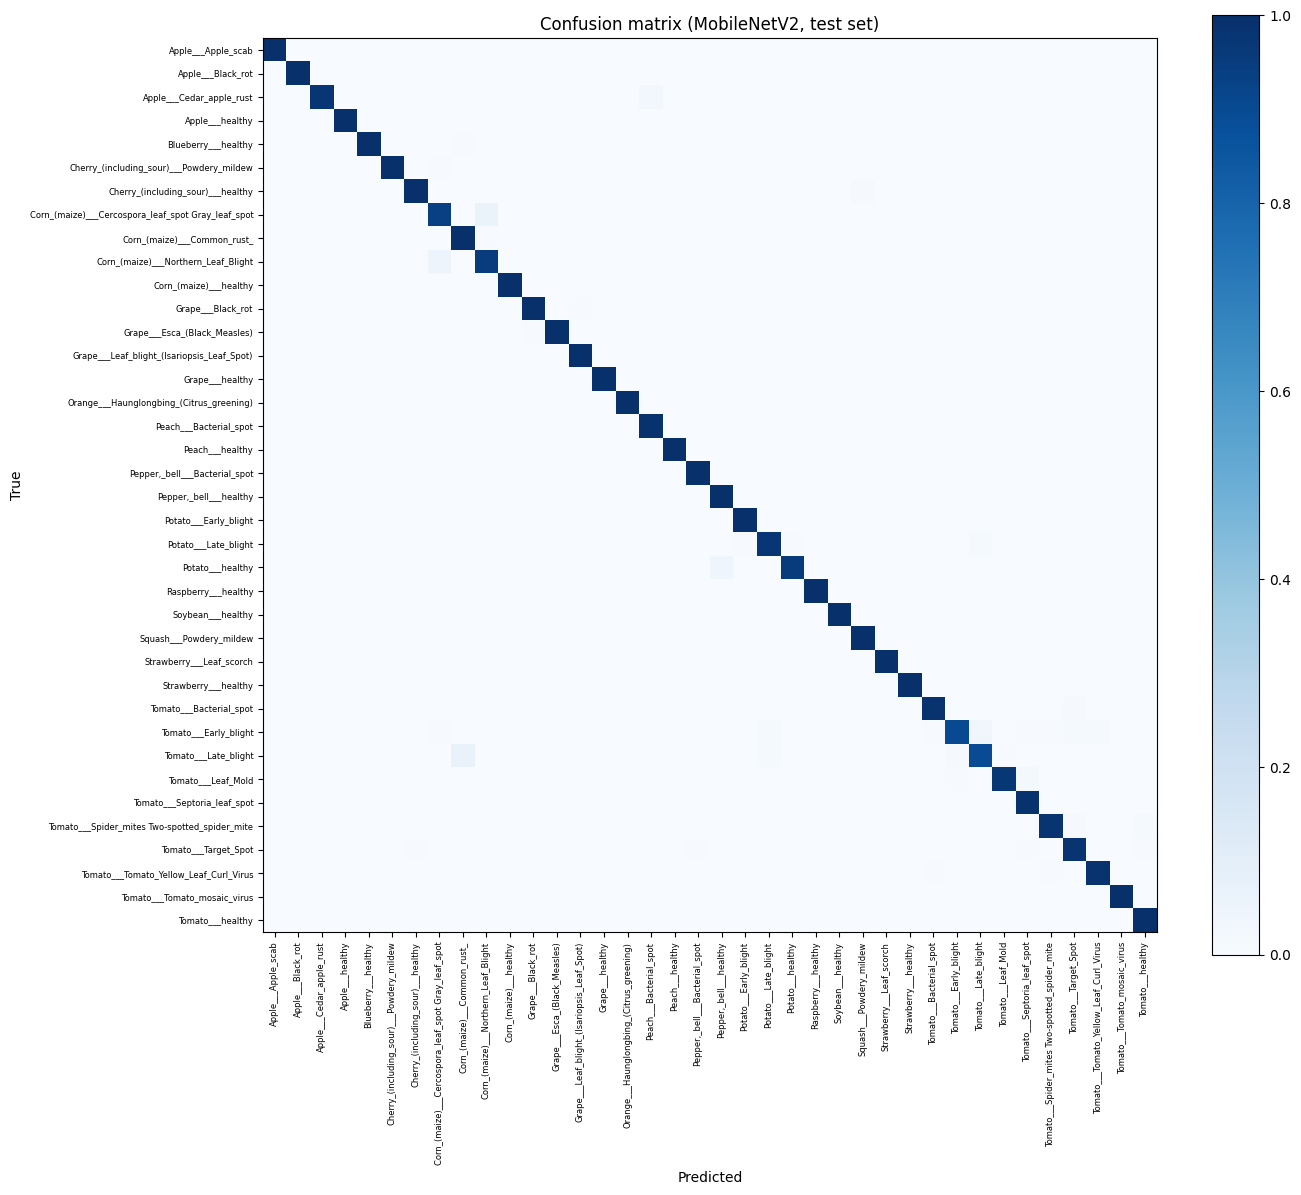

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.989     1.000     0.995        94
                                 Apple___Black_rot      1.000     1.000     1.000        93
                          Apple___Cedar_apple_rust      0.976     0.976     0.976        41
                                   Apple___healthy      1.000     1.000     1.000       246
                               Blueberry___healthy      1.000     0.996     0.998       226
          Cherry_(including_sour)___Powdery_mildew      1.000     0.994     0.997       158
                 Cherry_(including_sour)___healthy      0.992     0.992     0.992       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.878     0.935     0.906        77
                       Corn_(maize)___Common_rust_      0.894     0.994     0.942       179
               Corn_(maize)___Northern_Leaf_Blight      0.959     0.952     0.9

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from pathlib import Path

OUT = Path("/content/drive/MyDrive/plant-disease-cnn/outputs")
OUT.mkdir(parents=True, exist_ok=True)
base_path = "/content/drive/MyDrive/plant-disease-cnn/models/baseline_cnn.pth"

def predict_test(m):
    m.eval()
    preds, trues = [], []
    with torch.no_grad():
        for x, y in test_loader:
            with torch.autocast(device_type="cuda", enabled=use_amp):
                out = m(x)
            preds.append(out.argmax(1).cpu())
            trues.append(y.cpu())
    return torch.cat(preds).numpy(), torch.cat(trues).numpy()

# 1. Best MobileNetV2 on the test set
ckpt = torch.load(save_path_tl, map_location=device)
model.load_state_dict(ckpt["model_state"])
preds, trues = predict_test(model)

# 2. Baseline CNN on the same test set
base = BaselineCNN(num_classes=len(classes)).to(device)
base.load_state_dict(torch.load(base_path, map_location=device)["model_state"])
b_preds, _ = predict_test(base)

# 3. Side-by-side comparison
acc_tl, acc_b = (preds == trues).mean(), (b_preds == trues).mean()
f1_tl = f1_score(trues, preds, average="macro")
f1_b = f1_score(trues, b_preds, average="macro")
print(f"{'Model':<16}{'Test accuracy':>15}{'Macro F1':>12}")
print(f"{'Baseline CNN':<16}{acc_b:>15.4f}{f1_b:>12.4f}")
print(f"{'MobileNetV2':<16}{acc_tl:>15.4f}{f1_tl:>12.4f}")

# 4. Recall of the baseline's 5 weakest classes, before and after
cm = confusion_matrix(trues, preds)
cm_b = confusion_matrix(trues, b_preds)
rec_tl = cm.diagonal() / cm.sum(axis=1)
rec_b = cm_b.diagonal() / cm_b.sum(axis=1)
print("\nBaseline's weakest classes (recall: baseline -> MobileNetV2):")
for i in np.argsort(rec_b)[:5]:
    print(f"  {classes[i]}: {rec_b[i]:.3f} -> {rec_tl[i]:.3f}")

# 5. Training curves (stage change marked)
if "history_tl" in globals():
    ep = range(1, len(history_tl["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, history_tl["train_loss"], label="train")
    ax[0].plot(ep, history_tl["val_loss"], label="validation")
    ax[0].set_title("Loss")
    ax[1].plot(ep, history_tl["train_acc"], label="train")
    ax[1].plot(ep, history_tl["val_acc"], label="validation")
    ax[1].set_title("Accuracy")
    for a in ax:
        a.axvline(3.5, color="gray", linestyle="--")   # fine-tuning starts
        a.set_xlabel("Epoch")
        a.legend()
    plt.tight_layout()
    plt.savefig(OUT / "mobilenetv2_training_curves.png", dpi=150)
    plt.show()

# 6. Confusion matrix
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(cm_norm, cmap="Blues")
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90, fontsize=6)
ax.set_yticklabels(classes, fontsize=6)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix (MobileNetV2, test set)")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(OUT / "mobilenetv2_confusion_matrix.png", dpi=150)
plt.show()

# 7. Full report and the 5 weakest classes of the new model
print(classification_report(trues, preds, target_names=classes, digits=3))
print("MobileNetV2 weakest classes:")
for i in np.argsort(rec_tl)[:5]:
    print(f"  {classes[i]}: {rec_tl[i]:.3f} ({cm[i].sum()} test images)")

In [11]:
from pathlib import Path

root = Path("/content/drive/MyDrive/plant-disease-cnn")

def show(path, prefix=""):
    items = sorted(path.iterdir(), key=lambda p: (p.is_file(), p.name))
    for i, p in enumerate(items):
        last = i == len(items) - 1
        size = f"  ({p.stat().st_size / 1e6:.1f} MB)" if p.is_file() else ""
        print(prefix + ("└── " if last else "├── ") + p.name + size)
        if p.is_dir():
            show(p, prefix + ("    " if last else "│   "))

print(root.name + "/")
show(root)

plant-disease-cnn/
├── data
│   └── archive.zip  (2189.4 MB)
├── models
│   ├── baseline_cnn.pth  (1.6 MB)
│   └── mobilenetv2.pth  (9.3 MB)
└── outputs
    ├── confusion_matrix.png  (0.2 MB)
    ├── mobilenetv2_confusion_matrix.png  (0.2 MB)
    ├── mobilenetv2_training_curves.png  (0.1 MB)
    └── training_curves.png  (0.1 MB)
